# desilike on the run-1 samples, 5 vs 2.5 h⁻¹Mpc bins (exploratory)

**Question.** For every run-1 sample (Full, Fil, NonFil, Full diluted to N_Fil and to N_NonFil):
does desilike agree with our fitter, and what changes when the monopole is binned in
2.5 h⁻¹Mpc instead of 5 h⁻¹Mpc bins?

**Same inputs for both codes:** our ξ₀(s), our covariance (`gaussian_cov_pk` from the measured
spectra; the spectra do not depend on the binning, only the covariance sum does), MultiDark-Planck
cosmology (`bf.COSMO`), fit range 65–135 h⁻¹Mpc (14 bins at 5, 28 bins at 2.5).

**Three fits per sample and binning, in each code:**
* **α fit:** Σ ~ N(Σ_theory, 2), as `run_all`. Gives α and its 68% interval.
* **Σ fit:** flat prior 0 < Σ < 16, α free. Gives the best-fit Σ (profile). `run_all` quotes the
  *marginal* mean of Σ; desilike would need sampling (MCMC) for that, not done here.
* **no-wiggle fit:** same model without BAO. Δχ²_det = χ²(no-wiggle) − χ²(α fit, prior term included).

Not here: null-mock p-values and Δα/ΔΣ between samples (they stay in `run_all`).
The two random dilutions are fitted and listed in the tables and printouts, but left out of all plots.
A sample whose monopole file does not exist at a binning is skipped with a message.
Colours: blue = ours, orange = desilike. Nothing is written to disk.

In [1]:
import os, sys, warnings, time
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler

OURS, DESI, DATA = '#2a78d6', '#eb6834', '0.15'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

MONO = os.path.join(REPO, 'data/processed/monopoles/box')
pk_file = os.path.join(REPO, 'data/processed/pk/box/pk_XISMU_box_mag-21.2_dist_fil.npz')
binseps = (5.0, 2.5)
fit_range = (65., 135.)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit, as run_all

# sample -> label in the spectra file (= <bin_desc> of the monopole files written by the current script)
samples = {'Full': 'full',
           'Fil': '0.0leqd_mathrmfilleq3.0',
           'NonFil': '10.0leqd_mathrmfilleq100.0',
           'Full dil nFil': 'FullrandomN-559189r20261016',
           'Full dil nNonFil': 'FullrandomN-1003482r20261016'}

plot_samples = ['Full', 'Fil', 'NonFil']      # the dilutions appear in tables only

def monopole_file(key, binsep):
    # current naming ('leq') first, then the older one ('-'); None if neither exists
    for k in (key, key.replace('leqd', '-d')):
        f = os.path.join(MONO, f'mag=-21.2_sep=5.0-150.0_binsep={binsep:.1f}_{k}.npz')
        if os.path.exists(f):
            return f
    return None

C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']
spec = bf.load_spectra(pk_file)
print(f"Sigma prior of the alpha fit: N({Sigma_th:.2f}, 2);  spectra labels: {spec['labels']}")

Sigma prior of the alpha fit: N(7.78, 2);  spectra labels: ['full', '0.0leqd_mathrmfilleq3.0', '10.0leqd_mathrmfilleq100.0', 'FullrandomN-559189r20261016', 'FullrandomN-1003482r20261016']


## 1. Data and covariance at the two binnings

For each sample: N, the number of bins in the fit range, and the bias used in the covariance
(b from 40–70 h⁻¹Mpc; only its low-k part, as before). Then the monopoles at both binnings and
their errors √diag(C) (bottom row). The per-bin error barely changes with the bin width: it is
dominated by cosmic variance (the same long-wavelength modes move every bin, whatever its width);
only the shot-noise part grows (by ~√2 per halving), which is visible for Fil, the sample with the
largest (excess) shot noise. Neighbouring 2.5 bins are very strongly correlated, so the information
is almost the same (Fisher estimate of 10-16: σ_α unchanged, σ_Σ ~15% smaller for Fil).

Full               bin 5.0:  N =  2400560   14 bins in fit range   b(cov) = 1.032
Full               bin 2.5:  N =  2400560   28 bins in fit range   b(cov) = 1.032
Fil                bin 5.0:  N =   559189   14 bins in fit range   b(cov) = 1.374
Fil                bin 2.5:  N =   559189   28 bins in fit range   b(cov) = 1.375
WARNING bias estimate unstable across ranges: (30, 60): 0.671, (40, 70): 0.789, (35, 75): 0.739  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 at k < 0.08
NonFil             bin 5.0:  N =  1003482   14 bins in fit range   b(cov) = 0.789
WARNING bias estimate unstable across ranges: (30, 60): 0.670, (40, 70): 0.787, (35, 75): 0.737  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 at k < 0.08
NonFil             bin 2.5:  N =  1003482   28 bins in fit range   b(cov) = 0.787
Full dil nFil      bin 5.0:  N =   559189   14 bins in fit range   b(cov) = 1.035
SKIP Full dil nFil at 2.5: no monopole file (run scripts/multidark_a

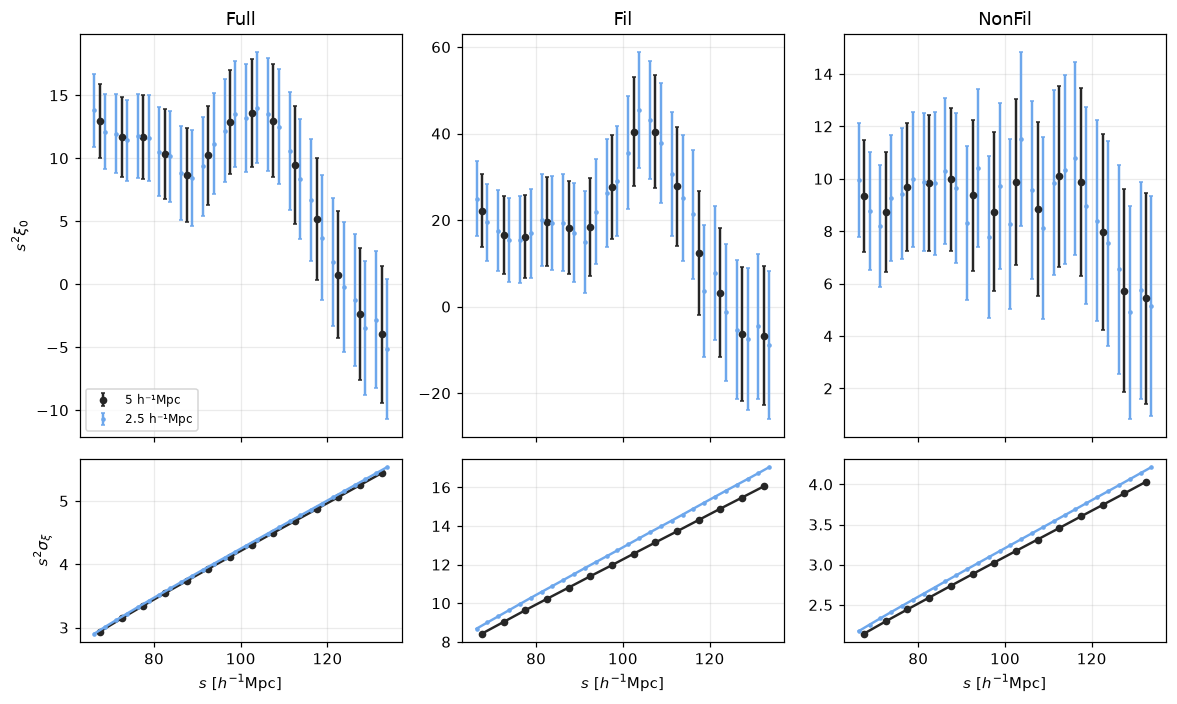

In [2]:
data = {}
for lab, key in samples.items():
    for bs in binseps:
        f = monopole_file(key, bs)
        if f is None:
            print(f"SKIP {lab} at {bs}: no monopole file (run scripts/multidark_analysis.py with bin_size_2d = {bs})")
            continue
        s, xi, n_gal = bf.load_monopole(f)
        edges = bf.edges_from_centres(s)
        i_spec = spec['labels'].index(key)
        assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
        b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
        C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b], lin)
        m = (s >= fit_range[0]) & (s <= fit_range[1])
        data[lab, bs] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b)
        print(f"{lab:<18} bin {bs}:  N = {n_gal:>8d}   {m.sum():>2d} bins in fit range   b(cov) = {b:.3f}")

labs = [l for l in samples if any((l, bs) in data for bs in binseps)]     # all samples (tables)
labs_p = [l for l in labs if l in plot_samples]                              # plotted samples
fig, axes = plt.subplots(2, len(labs_p), figsize=(3.6 * len(labs_p), 6.5), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
for j, lab in enumerate(labs_p):
    for bs, mk, c in ((5.0, 'o', '0.15'), (2.5, '.', '#6da7ec')):
        if (lab, bs) not in data: continue
        d = data[lab, bs]; s, m = d['s'], d['m']
        axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * d['sig'][m], fmt=mk, ms=4, capsize=1.5,
                            color=c, label=f'{bs:g} h⁻¹Mpc')
        axes[1, j].plot(s[m], s[m]**2 * d['sig'][m], mk + '-', ms=4, color=c)
    axes[0, j].set_title(lab); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$s^2\sigma_\xi$'); axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 1b. The measured power spectra, and what "excess noise" means

The covariance is built from these spectra (one auto-spectrum per sample, file `pk_XISMU_box_mag-21.2_dist_fil.npz`,
384³ grid, k_Nyq = 1.21 h/Mpc). Colours here = samples (not codes).

**Left:** P(k) of each sample (solid), shot noise not subtracted. Dotted: b²P_lin(k), the linear-theory
prediction with the sample's bias. Dashed horizontal: the Poisson shot noise 1/n̄. For a Poisson sample of a
linear density field, P = b²P_lin + 1/n̄: the curve would follow the dotted line at low k and flatten onto
the dashed line at high k.

**Right:** the "excess" [P(k) − b²P_lin(k)] · n̄: everything in the measured power that linear theory does
not explain, in units of Poisson shot noise. For a Poisson sample of a linear field it would be exactly 1
at every k. Above 1 means extra power: non-linear clustering of small groups (galaxies sharing haloes) and,
for Fil, any extra clumpiness from how DisPerSE selects filament galaxies. In the covariance it acts like
extra noise, which is why we call it "excess noise". The short dashed lines show the constant value the
covariance assumes above k = 0.6 k_Nyq = 0.72 (and up to infinite k): taken from the measured excess at
k ≈ 0.65–0.72. Where the solid curve keeps falling beyond that point, the covariance overestimates the
high-k noise. Vertical dotted lines: k = 0.08 (below it the covariance uses b²P_lin + N, too few modes),
0.6 k_Nyq and k_Nyq. Shaded: k < 0.3, where essentially all the BAO information is (section 1c).

Reading the right panel: below k ≈ 0.05 the curves scatter wildly (few modes in the box, plus the bias b is
only an estimate), so only k ≳ 0.05 is meaningful. Below k ≈ 0.3 part of Fil's "excess" is extra
*clustering* (its large-scale power is above b²P_lin with the b fitted at 40–70 h⁻¹Mpc), not noise; the
covariance uses the measured spectrum there, so that is not an assumption. The assumption is only the
dashed tail beyond 0.72. The printed table also lists the two random dilutions (not plotted): "Full dil nFil"
has the same n̄ as Fil but random galaxies, and its excess sits near 1 (Poisson) at all k, so Fil's extra
power comes from *which* galaxies are selected, not from how many.

sample               1/nbar  excess x nbar at k = 0.15, 0.3, 0.6, 1.0, 1.15   | value assumed above 0.72
Full                    417   1.49  1.85  1.63  1.44  1.40                  |  1.58
Fil                    1788   8.82  6.09  3.78  2.44  2.21                  |  3.35
NonFil                  997   2.55  1.75  1.38  1.21  1.19                  |  1.31
Full dil nFil          1788   1.13  1.21  1.15  1.10  1.10                  |  1.14
Full dil nNonFil        997   1.27  1.36  1.28  1.18  1.17                  |  1.24


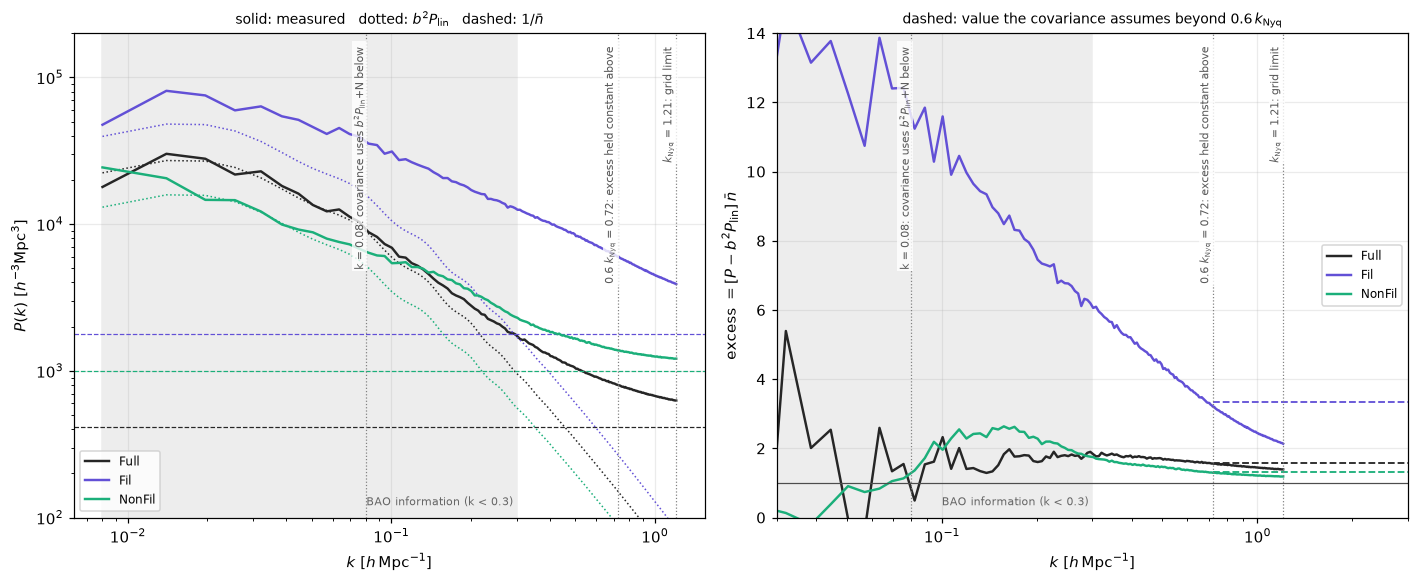

In [3]:
SCOL = {'Full': '0.15', 'Fil': '#6250d6', 'NonFil': '#1baf7a', 'Full dil nFil': '#eda100', 'Full dil nNonFil': '#e87ba4'}
kk, kNyq = spec['k'], spec['kNyq']
Plin = lambda x: np.exp(np.interp(np.log(x), np.log(lin['kh']), np.log(lin['pk'])))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.4))
print(f"{'sample':<18}{'1/nbar':>9}  excess x nbar at k = 0.15, 0.3, 0.6, 1.0, 1.15   | value assumed above 0.72")
for lab, key in samples.items():
    if (lab, 5.0) not in data: continue
    i = spec['labels'].index(key); nbar = spec['n_gal'][i] / bf.L_BOX**3; b = data[lab, 5.0]['b']; c = SCOL[lab]
    P = spec['P'][i, i]
    ex = (P - b**2 * Plin(kk)) * nbar
    _, ex_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, np.array([0.5]))
    if lab in plot_samples:
        a1.loglog(kk, P, color=c, label=lab)
        a1.loglog(kk, b**2 * Plin(kk), color=c, ls=':', lw=1)
        a1.axhline(1 / nbar, color=c, ls='--', lw=0.8)
        a2.semilogx(kk, ex, color=c, label=lab)
        a2.hlines(ex_tail * nbar, 0.6 * kNyq, 3.0, color=c, ls='--', lw=1.2)
    at = lambda x: np.interp(x, kk, ex)
    print(f"{lab:<18}{1/nbar:>9.0f}  {at(.15):5.2f} {at(.3):5.2f} {at(.6):5.2f} {at(1.0):5.2f} {at(1.15):5.2f}"
          f"                  | {ex_tail * nbar:5.2f}")
vlines = ((0.08, 'k = 0.08: covariance uses $b^2P_{\\rm lin}$+N below'),
          (0.6 * kNyq, '0.6 $k_{\\rm Nyq}$ = 0.72: excess held constant above'),
          (kNyq, '$k_{\\rm Nyq}$ = 1.21: grid limit'))
for a in (a1, a2):
    a.axvspan(kk[0], 0.3, color='0.93', zorder=0)
    a.text(0.3, 0.02, 'BAO information (k < 0.3) ', transform=a.get_xaxis_transform(), ha='right', va='bottom',
           fontsize=7, color='0.4')
    for x, txt in vlines:
        a.axvline(x, color='0.5', ls=':', lw=0.8)
        a.text(x, 0.98, txt + ' ', transform=a.get_xaxis_transform(), rotation=90, ha='right', va='top',
               fontsize=7, color='0.35', bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
    a.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a1.set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); a1.set_ylim(1e2, 2e5); a1.legend(fontsize=8, loc='lower left')
a1.set_title('solid: measured   dotted: $b^2P_{\\rm lin}$   dashed: $1/\\bar n$', fontsize=9)
a2.axhline(1, color='0.3', lw=0.8); a2.set_xlim(0.03, 3.0); a2.set_ylim(0, 14)
a2.set_ylabel(r'excess $=[P - b^2P_{\rm lin}]\,\bar n$'); a2.legend(fontsize=8, loc='center right')
a2.set_title('dashed: value the covariance assumes beyond $0.6\\,k_{\\rm Nyq}$', fontsize=9)
fig.tight_layout(); plt.show()

### The spectrum that actually enters the covariance

The plots above show the *measured* spectra. The covariance uses a patched version, P_cov(k), built by
`bf.spectrum_for_cov` and evaluated on the box's discrete modes (|k| = 2π|n|/L) up to k = 3 h/Mpc:

| k range [h/Mpc] | P_cov(k) | why |
|---|---|---|
| k < 0.08 | b²P_lin(k) + N_low, with N_low = mean excess at 0.10–0.20 | few modes, measurement noisy |
| 0.08–0.15 | linear blend of the two | smooth transition |
| 0.15–0.72 | the measured P(k) | well measured |
| 0.72–3 | b²P_lin(k) + N_tail, N_tail = mean excess at 0.65–0.72 | close to the grid limit |
| > 3 | constant N_tail (added analytically, Parseval) | — |

0.72 = 0.6 k_Nyq, with k_Nyq = π · ng / L = π · 384 / 1000 = 1.21 h/Mpc set by `pk_ngrid` in
`multidark_analysis.py`. The factor 0.6 is a choice in `spectrum_for_cov` (`kuse_frac=0.6`): near k_Nyq the
measurement is affected by aliasing and the grid-assignment window, so the last 40% is not trusted.

Top row: measured spectrum (grey) and P_cov (colour) for each sample; shading marks the four regions.
Bottom row: P_cov / P_measured where both exist. Ratios ≠ 1 show where the covariance is not using the
measurement: at low k (the bias model), and above 0.72 for Fil, where P_cov stays above the measured
spectrum because the measured excess keeps falling.

**Why the measured P(k) is not used below k ≈ 0.08.** The box contains only a few long-wavelength modes.
The power in each single mode fluctuates randomly by about 100% of its mean (that is the Gaussian property
the covariance formula itself uses), and the measured P(k) in a k bin is the average over the modes in that
bin, so its scatter is about 1/√N for N independent modes (k and −k are the same mode, so N is half the
number of grid modes). The cell below counts them from the spectra file:

| k [h/Mpc] | 0.008 | 0.02 | 0.04 | 0.08 | 0.15 | 0.3 |
|---|---|---|---|---|---|---|
| independent modes | 9 | 49 | 225 | 1089 | 3565 | 14533 |
| scatter of the measured P | 33% | 14% | 7% | 3% | 1.7% | 0.8% |

The covariance needs the *expected* P(k) (the average over many universes), not this box's particular
random values, and P enters it squared, so a 14% fluctuation would become ~30% in the covariance. Below
k ≈ 0.08 the measurement is too noisy to stand in for the expectation, so the smooth model b²P_lin + N is
used there; above 0.15 the scatter is below 2% and the measurement is used directly; in between the two are
blended. The model only enters where the data cannot pin down the average.

In [4]:
nm = spec['nmodes']
print(f"k bin width = {kk[1] - kk[0]:.4f} h/Mpc")
print(f"{'k':>8}{'grid modes':>12}{'independent':>13}{'scatter 1/sqrt(N)':>19}")
for kx in (0.008, 0.02, 0.04, 0.08, 0.15, 0.3):
    i = np.argmin(abs(kk - kx))
    print(f"{kk[i]:>8.4f}{nm[i]:>12.0f}{nm[i] / 2:>13.0f}{1 / np.sqrt(nm[i] / 2):>19.3f}")

k bin width = 0.0060 h/Mpc
       k  grid modes  independent  scatter 1/sqrt(N)
  0.0080          18            9              0.333
  0.0197          98           49              0.143
  0.0385         450          225              0.067
  0.0820        2178         1089              0.030
  0.1509        7130         3565              0.017
  0.3016       29066        14533              0.008


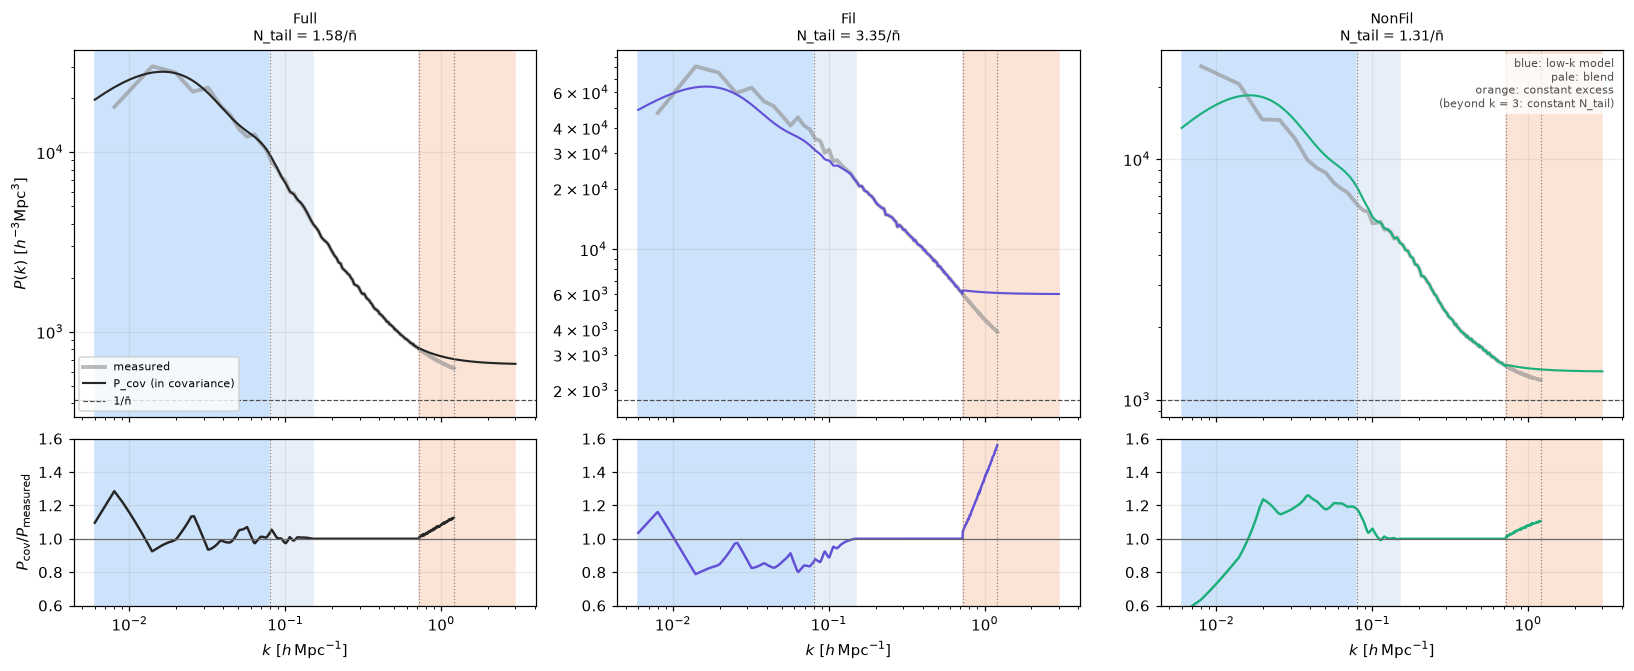

In [9]:
kgrid = np.linspace(0.006, 3.0, 3000)
labs_s = [l for l in plot_samples if (l, 5.0) in data]
fig, axes = plt.subplots(2, len(labs_s), figsize=(5 * len(labs_s), 6.2), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.2, 1)), squeeze=False)
regions = ((0.006, 0.08, '#cde2fb'), (0.08, 0.15, '#e6eef8'), (0.6 * kNyq, 3.0, '#fbe3d6'))
for j, lab in enumerate(labs_s):
    key = samples[lab]; i = spec['labels'].index(key); b = data[lab, 5.0]['b']; c = SCOL[lab]
    Pcov, N_tail = bf.spectrum_for_cov(spec, i, i, b, b, lin, kgrid)
    P = spec['P'][i, i]
    ax, axr = axes[0, j], axes[1, j]
    for lo, hi, col in regions:
        ax.axvspan(lo, hi, color=col, zorder=0); axr.axvspan(lo, hi, color=col, zorder=0)
    ax.loglog(kk, P, color='0.55', lw=2.5, alpha=0.6, label='measured')
    ax.loglog(kgrid, Pcov, color=c, lw=1.4, label='P_cov (in covariance)')
    nbar = spec['n_gal'][i] / bf.L_BOX**3
    ax.axhline(1 / nbar, color='0.3', ls='--', lw=0.8, label='1/n̄')
    ax.set_title(f"{lab}\nN_tail = {N_tail * nbar:.2f}/n̄", fontsize=9)
    m_ = kgrid <= kNyq
    axr.semilogx(kgrid[m_], Pcov[m_] / np.interp(kgrid[m_], kk, P), color=c)
    axr.axhline(1, color='0.4', lw=0.8); axr.set_ylim(0.6, 1.6); axr.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
    for x in (0.08, 0.6 * kNyq, kNyq):
        ax.axvline(x, color='0.5', ls=':', lw=0.8); axr.axvline(x, color='0.5', ls=':', lw=0.8)
axes[0, 0].set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); axes[1, 0].set_ylabel(r'$P_{\rm cov}/P_{\rm measured}$')
axes[0, 0].legend(fontsize=7, loc='lower left')
axes[0, -1].text(0.98, 0.98, 'blue: low-k model\npale: blend\norange: constant excess\n(beyond k = 3: constant N_tail)',
                 transform=axes[0, -1].transAxes, ha='right', va='top', fontsize=7, color='0.3',
                 bbox=dict(fc='white', ec='none', alpha=0.8, pad=2))
fig.tight_layout(); plt.show()

## 1c. Where the BAO information lives (the math behind "no BAO signal above k ≈ 0.3")

**The wiggles.** In Fourier space the BAO is the oscillation O(k) = P_lin/P_nw − 1, with period
2π/r_d ≈ 0.063 h/Mpc (r_d = 100.07 h⁻¹Mpc). Its amplitude already decays with k in linear theory (Silk
damping), and non-linear motions multiply it by D(k) = exp(−k²Σ²/2) with Σ = 7.78 h⁻¹Mpc:

| k [h/Mpc] | 0.1 | 0.2 | 0.3 | 0.4 | 0.6 |
|---|---|---|---|---|---|
| D(k) | 0.74 | 0.30 | 0.066 | 0.008 | 2·10⁻⁵ |
| undamped wiggle amplitude | 0.066 | 0.038 | 0.014 | 0.004 | 0.0003 |
| damped wiggle amplitude | 0.049 | 0.011 | 0.0009 | 3·10⁻⁵ | ~0 |

**The peak width.** Multiplying by a Gaussian in k is the same as smoothing with a Gaussian of width Σ in s.
In our template the BAO bump s²(ξ − ξ_nw) has FWHM 19.2 h⁻¹Mpc undamped and 25.2 h⁻¹Mpc with Σ = 7.78.

**Information on α.** The standard Fourier-space (Seo & Eisenstein) Fisher information for α,
F(k_max) = V/(4π²) ∫₀^{k_max} k² dk [∂P/∂α / (P + 1/n̄)]², with ∂P/∂α = −b² k O′(k) D(k) P_nw (only the
wiggles are dilated), accumulates almost entirely below k ≈ 0.25 (left panel below; Full: 60% below 0.15,
89% below 0.2, 99.8% below 0.3). It only counts the BAO wiggles, which is why it gives σ_α ≈ 0.017, tighter
than our fit to 65–135 h⁻¹Mpc with a free broadband (0.029).

**What binning does.** Averaging j₀(ks) over a bin of width Δs multiplies each Fourier mode by about
sin(x)/x with x = kΔs/2 (right panel). For Δs = 5 h⁻¹Mpc it is 0.91 at k = 0.3, 0.64 at k = π/Δs = 0.63 and
0 at 2π/Δs = 1.26; for Δs = 2.5 the same happens at twice those k. So 5 h⁻¹Mpc bins keep > 90% of every
mode that carries BAO information. 2.5 bins add modes at k ≈ 0.6–2.5, where there is no BAO signal, only
the high-k noise of section 1b (whose treatment in the covariance is the weak point).

Full: fraction of the alpha information from k < 0.15: 0.600
Full: fraction of the alpha information from k < 0.2: 0.885
Full: fraction of the alpha information from k < 0.3: 0.998
Fil: fraction of the alpha information from k < 0.15: 0.645
Fil: fraction of the alpha information from k < 0.2: 0.909
Fil: fraction of the alpha information from k < 0.3: 0.999


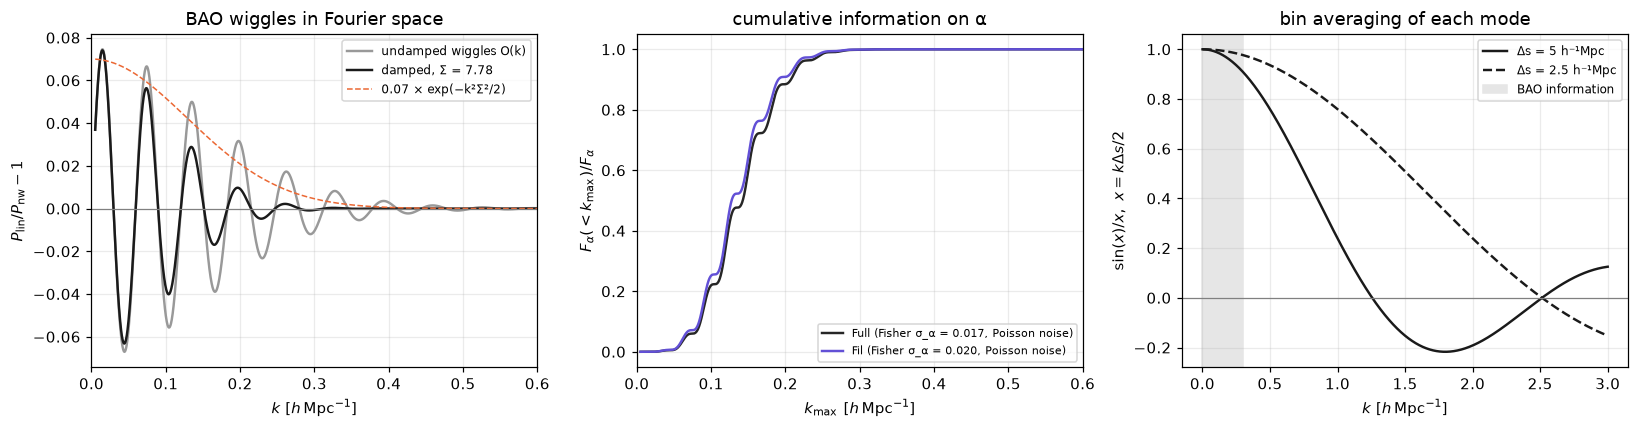

In [6]:
S_, rd_ = Sigma_th, lin['rd']
kf = np.linspace(0.005, 1.0, 4000)
Pl_, Pn_ = np.interp(kf, k, P_w), np.interp(kf, k, P_nw)
O_ = Pl_ / Pn_ - 1; D_ = np.exp(-kf**2 * S_**2 / 2)
fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(15, 4))
a0.plot(kf, O_, color='0.6', label='undamped wiggles O(k)')
a0.plot(kf, O_ * D_, color='0.1', label=f'damped, Σ = {S_:.2f}')
a0.plot(kf, 0.07 * D_, color='#eb6834', ls='--', lw=1, label='0.07 × exp(−k²Σ²/2)')
a0.axhline(0, color='0.5', lw=0.8); a0.set_xlim(0, 0.6); a0.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a0.set_ylabel(r'$P_{\rm lin}/P_{\rm nw}-1$'); a0.legend(fontsize=8); a0.set_title('BAO wiggles in Fourier space')
for lab in ('Full', 'Fil'):
    i = spec['labels'].index(samples[lab]); nbar = spec['n_gal'][i] / bf.L_BOX**3; b2 = data[lab, 5.0]['b']**2
    dPda = -kf * np.gradient(O_, kf) * D_ * Pn_ * b2
    Ptot = b2 * Pn_ * (1 + O_ * D_) + 1 / nbar
    F = np.cumsum(kf**2 * (dPda / Ptot)**2) * (kf[1] - kf[0]) * bf.L_BOX**3 / (4 * np.pi**2)
    a1.plot(kf, F / F[-1], color=SCOL[lab], label=f'{lab} (Fisher σ_α = {1/np.sqrt(F[-1]):.3f}, Poisson noise)')
    for km in (0.15, 0.2, 0.3):
        print(f"{lab}: fraction of the alpha information from k < {km}: {F[np.searchsorted(kf, km)] / F[-1]:.3f}")
a1.set_xlim(0, 0.6); a1.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$F_\alpha(<k_{\max})/F_\alpha$')
a1.legend(fontsize=7); a1.set_title('cumulative information on α')
kb = np.linspace(1e-3, 3, 2000)
for ds, ls in ((5., '-'), (2.5, '--')):
    a2.plot(kb, np.sinc(kb * ds / 2 / np.pi), color='0.1', ls=ls, label=f'Δs = {ds:g} h⁻¹Mpc')
a2.axvspan(0, 0.3, color='0.9', zorder=0, label='BAO information')
a2.axhline(0, color='0.5', lw=0.8); a2.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$')
a2.set_ylabel(r'$\sin(x)/x,\ x = k\Delta s/2$'); a2.legend(fontsize=8); a2.set_title('bin averaging of each mode')
fig.tight_layout(); plt.show()

### Where Σ = 7.78 h⁻¹Mpc comes from

Σ is the typical distance by which two galaxies that started r_d ≈ 100 h⁻¹Mpc apart have moved *relative to
each other* since early times. That relative motion smears the BAO peak. It is computed from linear theory
with the Zel'dovich approximation (ESW07 §4–5; Chen+24 eq. 9), in `bf.sigma_nl_theory`.

1. **Displacement field.** In the Zel'dovich approximation each galaxy moves by Ψ(q), with
   Ψ(k) = i k δ(k)/k² in Fourier space (the gradient of the linear potential). So the power spectrum of each
   Cartesian component is P_lin(k)/k² times the square of that component's direction cosine.
2. **One galaxy.** The variance of one component of the displacement of a single galaxy is
   σ₁² = (1/3) ∫ d³k/(2π)³ P_lin(k)/k² = (1/3) ∫ dk/(2π²) P_lin(k).
3. **Two galaxies a distance r apart.** Long waves (k ≪ 1/r) move both together and cancel in the
   difference; short waves move them independently. Averaged over directions, the variance per component of
   Ψ(x) − Ψ(x + r) is

   **Σ² = (2/3) ∫₀^∞ dk/(2π²) P_lin(k) [1 − j₀(k r)]**,  with j₀(x) = sin x / x and r = r_d.

   The factor 1 − j₀(k r_d) is ≈ 0 for k ≪ 1/r_d and → 1 for k ≫ 1/r_d. (Along and across the separation the
   two components differ by ± j₂ terms; their monopole average leaves only the j₀ term.)
4. **Numbers.** With the MultiDark-Planck P_lin at z = 0 (σ₈ = 0.8228) this gives Σ = 7.78 h⁻¹Mpc. Σ scales
   linearly with the amplitude of P_lin, i.e. with σ₈ (that is why the old template, σ₈ = 0.813, gave 7.67).
   The single-galaxy value σ₁ is printed too: the √2 relation (Σ ≈ √2 σ₁ for r → ∞) is why an earlier, one-galaxy
   estimate (~5.8) was too small.

Left: the integrand per ln k, dΣ²/d ln k = (2/3) k P_lin(k) [1 − j₀(k r_d)]/(2π²), and the same without the
[1 − j₀] factor (dotted). Right: Σ accumulated up to k_max. Most of Σ² comes from k ≈ 0.02–0.3 h/Mpc
(wavelengths ~20–300 h⁻¹Mpc; 82% of Σ²): large-scale flows, well described by linear theory. Modes below
k ≈ 0.02 move both galaxies together and contribute little (5%); modes above 0.3 still add ~13% of Σ², where
linear theory is less accurate (one reason the fit uses a Gaussian prior of width 2 around 7.78, not a fixed value).

In [7]:
kh, Pk, rd = lin['kh'], lin['pk'], lin['rd']
j0 = np.sinc(kh * rd / np.pi)
dS2_dlnk = (2. / 3.) * kh * Pk * (1. - j0) / (2 * np.pi**2)          # integrand per ln k
dS2_dlnk_one = (2. / 3.) * kh * Pk / (2 * np.pi**2)                    # same without the pair factor
lnk = np.log(kh)
S2_cum = np.concatenate([[0.], np.cumsum(0.5 * (dS2_dlnk[1:] + dS2_dlnk[:-1]) * np.diff(lnk))])
Sigma_calc = np.sqrt(S2_cum[-1])
sigma1 = np.sqrt(np.trapezoid(Pk, kh) / (3 * 2 * np.pi**2))
print(f"r_d = {rd:.2f} h^-1 Mpc,  sigma_8 = {lin['sigma8']:.4f}")
print(f"Sigma (pairwise, this cell) = {Sigma_calc:.3f}   bf.sigma_nl_theory = {Sigma_th:.3f} h^-1 Mpc")
print(f"sigma_1 (one galaxy, per axis) = {sigma1:.3f};  sqrt(2) sigma_1 = {np.sqrt(2) * sigma1:.3f} (pairwise limit for r -> infinity)")
for km in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5):
    print(f"  Sigma from k < {km:<4}: {np.sqrt(np.interp(np.log(km), lnk, S2_cum)):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.semilogx(kh, dS2_dlnk, color='0.1', label=r'$\frac{2}{3}\,k P_{\rm lin}\,[1-j_0(k r_d)]/2\pi^2$')
a1.semilogx(kh, dS2_dlnk_one, color='0.6', ls=':', label='without $[1-j_0]$ (no pair cancellation)')
a1.axvline(1 / rd, color='#eb6834', ls='--', lw=1, label=r'$k = 1/r_d$')
a1.set_xlim(1e-3, 3); a1.set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$'); a1.set_ylabel(r'$d\Sigma^2/d\ln k\ [h^{-2}{\rm Mpc}^2]$')
a1.legend(fontsize=8); a1.set_title('which scales smear the BAO')
a2.semilogx(kh, np.sqrt(S2_cum), color='0.1')
a2.axhline(Sigma_th, color='#eb6834', ls='--', lw=1, label=f'Σ = {Sigma_th:.2f}')
a2.set_xlim(1e-3, 3); a2.set_xlabel(r'$k_{\max}\ [h\,{\rm Mpc}^{-1}]$'); a2.set_ylabel(r'$\Sigma(<k_{\max})\ [h^{-1}{\rm Mpc}]$')
a2.legend(fontsize=8); a2.set_title('Σ accumulated up to $k_{\\max}$')
fig.tight_layout(); plt.show()

r_d = 100.07 h^-1 Mpc,  sigma_8 = 0.8228
Sigma (pairwise, this cell) = 7.779   bf.sigma_nl_theory = 7.779 h^-1 Mpc
sigma_1 (one galaxy, per axis) = 5.961;  sqrt(2) sigma_1 = 8.430 (pairwise limit for r -> infinity)
  Sigma from k < 0.02: 1.81
  Sigma from k < 0.05: 4.63
  Sigma from k < 0.1 : 6.05
  Sigma from k < 0.2 : 6.94
  Sigma from k < 0.3 : 7.26
  Sigma from k < 0.5 : 7.51


KeyboardInterrupt: 

## 2. The fits

desilike settings as in `desilike_test_full.ipynb`: real space (`dbeta` = 0, `sigmas` = 0),
isotropic damping (`sigmapar` = `sigmaper`), broadband a₀ + a₁/s + a₂/s², Wallisch no-wiggle
(`with_now='wallish2018'`), model averaged over each data bin (`wmatrix={'resolution': 10}`),
Minuit. Ours: `bf.fit_bao`, what `run_all` calls. Takes a few minutes (each desilike fit
recomputes its template).

In [ ]:
def desilike_lik(d, bs, prior='gauss', only_now=False):
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=2., limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], bs)}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open, as bf.fit_bao does
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

res = {}
t0 = time.time()
for (lab, bs), d in data.items():
    s, xi, C, e = d['s'], d['xi'], d['C'], d['edges']
    kw = dict(T=T, fit_range=fit_range, Sigma_theory=Sigma_th, s_edges=e)
    o_a = bf.fit_bao(s, xi, C, Sigma_prior=('gauss', 'theory', 2.0), **kw)
    o_S = bf.fit_bao(s, xi, C, Sigma_prior=('flat',) + Sigma_free, **kw)
    lik_a, obs_a = desilike_lik(d, bs, 'gauss'); d_a = desilike_fit(lik_a, interval=True)
    lik_S, _ = desilike_lik(d, bs, 'flat');      d_S = desilike_fit(lik_S)
    lik_n, obs_n = desilike_lik(d, bs, only_now=True); d_n = desilike_fit(lik_n)
    lik_a(**d_a['pars']); model_a = np.array(obs_a.flattheory)
    prior_term = ((d_a['pars']['sigmaper'] - Sigma_th) / 2.)**2
    res[lab, bs] = dict(ours=o_a, ours_S=o_S, des=d_a, des_S=d_S, des_nw=d_n, lik_a=lik_a, model_d=model_a,
                        model_o=bf.best_models(o_a, s, e)[0],
                        det_d=d_n['chi2'] - d_a['chi2'] - prior_term, chi2_d=d_a['chi2'] + prior_term)
    print(f"{lab:<18} bin {bs}: alpha ours {o_a['alpha']:.4f}  desilike {d_a['pars']['qiso']:.4f}   "
          f"({time.time() - t0:.0f} s)")

Full               bin 5.0: alpha ours 0.9861  desilike 0.9856   (21 s)


Full               bin 2.5: alpha ours 0.9856  desilike 0.9849   (44 s)


Fil                bin 5.0: alpha ours 0.9889  desilike 0.9883   (62 s)


Fil                bin 2.5: alpha ours 0.9878  desilike 0.9874   (81 s)


NonFil             bin 5.0: alpha ours 0.8996  desilike 0.8988   (103 s)


NonFil             bin 2.5: alpha ours 0.9119  desilike 0.9104   (126 s)


Full dil nFil      bin 5.0: alpha ours 0.9995  desilike 0.9991   (148 s)


Full dil nNonFil   bin 5.0: alpha ours 0.9965  desilike 0.9959   (167 s)


Full dil nNonFil   bin 2.5: alpha ours 0.9955  desilike 0.9951   (190 s)


## 3. Best fits at 2.5 h⁻¹Mpc

Data with errors, both codes' best α-fit models, and normalised residuals (ξ − model)/σ.
Neighbouring residuals move together: the bins are strongly correlated, so a run of same-sign
residuals is normal.

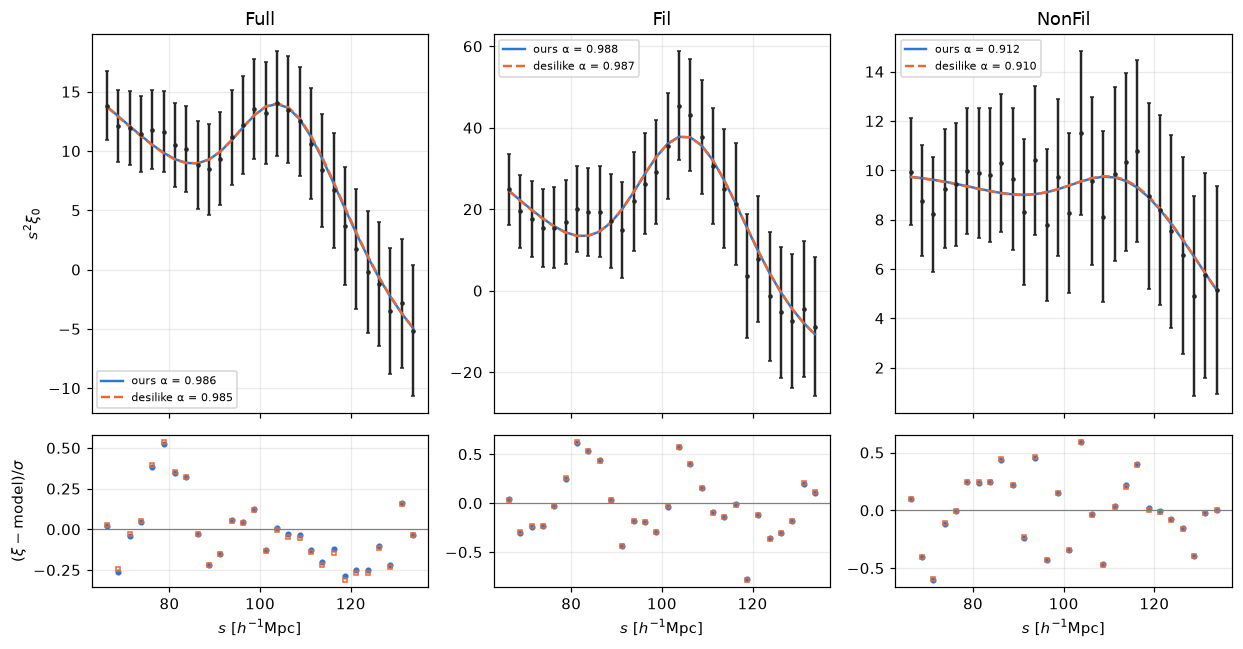

In [ ]:
labs25 = [l for l in plot_samples if (l, 2.5) in res]
fig, axes = plt.subplots(2, len(labs25), figsize=(3.8 * len(labs25), 6), sharex=True,
                         gridspec_kw=dict(height_ratios=(2.5, 1)), squeeze=False)
for j, lab in enumerate(labs25):
    d, r = data[lab, 2.5], res[lab, 2.5]; s, m, sg = d['s'], d['m'], d['sig']
    axes[0, j].errorbar(s[m], s[m]**2 * d['xi'][m], yerr=s[m]**2 * sg[m], fmt='.', ms=4, capsize=1.5, color=DATA)
    axes[0, j].plot(s[m], s[m]**2 * r['model_o'][m], color=OURS, label=f"ours α = {r['ours']['alpha']:.3f}")
    axes[0, j].plot(s[m], s[m]**2 * r['model_d'], color=DESI, ls='--', label=f"desilike α = {r['des']['pars']['qiso']:.3f}")
    axes[1, j].plot(s[m], (d['xi'][m] - r['model_o'][m]) / sg[m], 'o', ms=3, color=OURS)
    axes[1, j].plot(s[m], (d['xi'][m] - r['model_d']) / sg[m], 's', ms=3, mfc='none', color=DESI)
    axes[1, j].axhline(0, color='0.5', lw=0.8); axes[1, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    axes[0, j].set_title(lab); axes[0, j].legend(fontsize=7)
axes[0, 0].set_ylabel(r'$s^2\xi_0$'); axes[1, 0].set_ylabel(r'$(\xi-{\rm model})/\sigma$')
fig.tight_layout(); plt.show()

## 4. χ²(α) profiles, 5 vs 2.5, both codes

Δχ² relative to each curve's minimum; dotted line Δχ² = 1. Solid = 5 h⁻¹Mpc, dashed = 2.5.
If the binning carries the same information, solid and dashed have the same width (they can be
shifted: the two binnings are not the same numbers, so α can move within its error).
NonFil: α is not constrained (the curve stays flat inside 0.8–1.2).

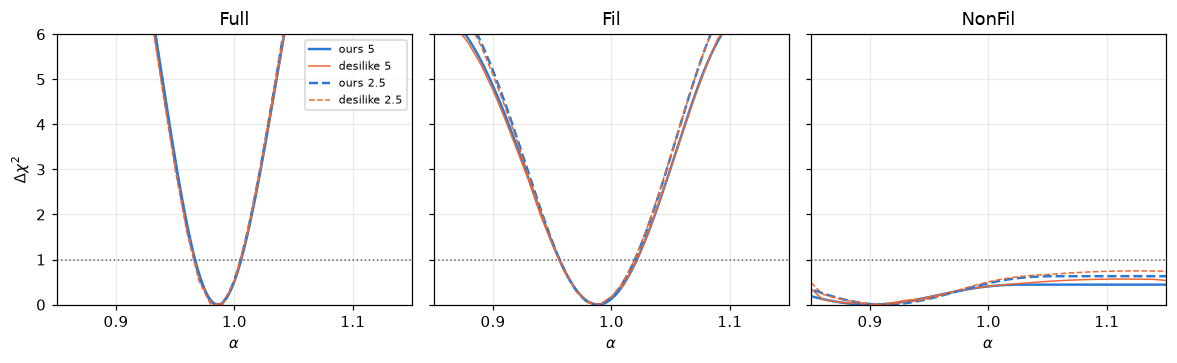

In [ ]:
grid = np.linspace(0.85, 1.15, 31)
fig, axes = plt.subplots(1, len(labs_p), figsize=(3.6 * len(labs_p), 3.4), sharey=True, squeeze=False)
for j, lab in enumerate(labs_p):
    ax = axes[0, j]
    for bs, ls in ((5.0, '-'), (2.5, '--')):
        if (lab, bs) not in res: continue
        r = res[lab, bs]
        ax.plot(r['ours']['alpha_grid'], r['ours']['prof_alpha'] - r['ours']['prof_alpha'].min(),
                color=OURS, ls=ls, label=f'ours {bs:g}')
        prof = MinuitProfiler(r['lik_a'], seed=42)
        prof.profile(params=['qiso'], grid=grid)
        pr = np.asarray(prof.profiles.profile['qiso'])
        ax.plot(pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max()), color=DESI, ls=ls, lw=1, label=f'desilike {bs:g}')
    ax.axhline(1, color='0.4', ls=':', lw=1); ax.set_xlim(grid[0], grid[-1]); ax.set_ylim(0, 6)
    ax.set_xticks([0.9, 1.0, 1.1])
    ax.set_title(lab); ax.set_xlabel(r'$\alpha$')
axes[0, 0].set_ylabel(r'$\Delta\chi^2$'); axes[0, 0].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 5. Summary table

* α, [68%]: α fit, profile best fit and Δχ² = 1 interval (`open` if it leaves 0.8–1.2).
* Σ: Σ fit (flat prior), profile best fit. Ours also gives the marginal mean ⟨Σ⟩ that `run_all`
  quotes; desilike's would need sampling.
* χ²/dof of the α fit (prior term included); dof = bins − 6.
* Δχ²_det = χ²(no-wiggle) − χ²(α fit), `run_all` convention.

In [ ]:
def fmt_a(a, lo, hi):
    f = lambda x: 'open' if not np.isfinite(x) else f'{x:.3f}'
    return f"{a:.4f} [{f(lo)}, {f(hi)}]"

hdr = (f"{'sample':<17}{'bin':>4} | {'alpha ours':<25}{'alpha desilike':<25}| {'Sigma o / d  <Sigma> o':<24}"
       f"| {'chi2/dof o / d':<17}| {'dchi2_det o / d':<15}")
print(hdr); print('-' * len(hdr))
for lab in labs:
    for bs in binseps:
        if (lab, bs) not in res: continue
        r = res[lab, bs]; o, oS, dd, dS = r['ours'], r['ours_S'], r['des'], r['des_S']
        dof = int(data[lab, bs]['m'].sum()) - 6
        print(f"{lab:<17}{bs:>4g} | {fmt_a(o['alpha'], o['lo'], o['hi']):<25}"
              f"{fmt_a(dd['pars']['qiso'], dd.get('lo', np.nan), dd.get('hi', np.nan)):<25}| "
              f"{oS['Sigma']:>5.2f} / {dS['pars']['sigmaper']:>5.2f}  {oS['Sigma_marg']['mean']:>5.2f}    | "
              f"{o['chi2_min']:>5.1f} / {r['chi2_d']:>5.1f} /{dof:<3d}| {o['dchi2_wiggle']:>5.2f} / {r['det_d']:>5.2f}")

sample            bin | alpha ours               alpha desilike           | Sigma o / d  <Sigma> o  | chi2/dof o / d   | dchi2_det o / d
----------------------------------------------------------------------------------------------------------------------------------------
Full                5 | 0.9861 [0.967, 1.006]    0.9856 [0.966, 1.005]    |  2.73 /  2.51   6.43    |   7.1 /   7.2 /8  | 12.24 / 10.60
Full              2.5 | 0.9856 [0.966, 1.005]    0.9849 [0.966, 1.005]    |  3.05 /  2.92   7.11    |  15.4 /  15.2 /22 | 13.06 /  8.62
Fil                 5 | 0.9889 [0.956, 1.022]    0.9883 [0.956, 1.022]    |  0.00 /  0.01   9.88    |   3.1 /   3.1 /8  |  6.41 /  5.61
Fil               2.5 | 0.9878 [0.956, 1.020]    0.9874 [0.956, 1.020]    |  0.00 /  0.02   9.98    |   7.1 /   7.1 /22 |  7.13 /  5.94
NonFil              5 | 0.8996 [open, open]      0.8988 [open, open]      |  0.00 /  0.08  10.32    |   3.4 /   3.4 /8  |  0.44 /  0.32
NonFil            2.5 | 0.9119 [open, open]   

## 6. What changes from 5 to 2.5 h⁻¹Mpc

Left: α with its 68% interval per sample, both binnings and both codes (NonFil omitted if its
interval is open). Right: Δχ²_det per sample. Dilutions: see the table in section 5. The two binnings use the same galaxies and the
same pairs, so they are strongly correlated; differences should be a fraction of the error bar.

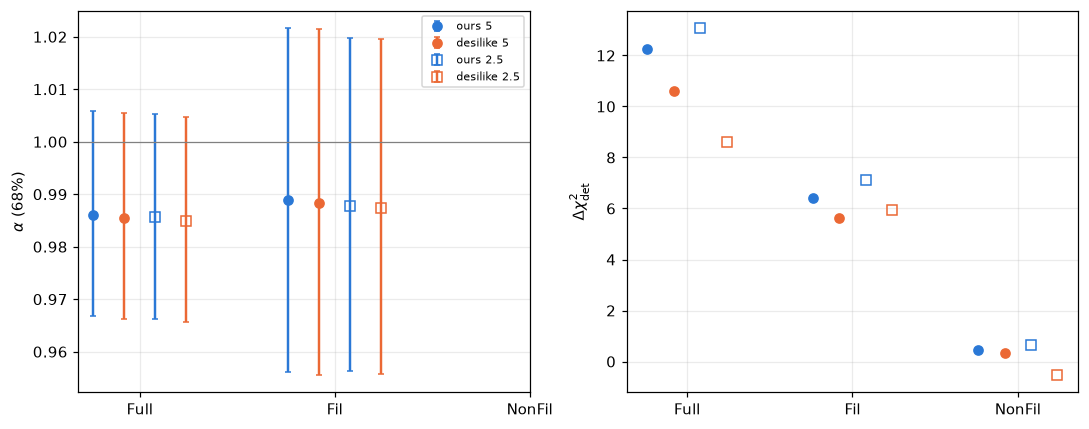

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(labs_p))
for k_, (bs, mk) in enumerate(((5.0, 'o'), (2.5, 's'))):
    for c_, (code_, col) in enumerate((('ours', OURS), ('des', DESI))):
        dx = -0.24 + 0.16 * (2 * k_ + c_)
        for j, lab in enumerate(labs_p):
            if (lab, bs) not in res: continue
            r = res[lab, bs]
            if code_ == 'ours':
                a, lo, hi, det = r['ours']['alpha'], r['ours']['lo'], r['ours']['hi'], r['ours']['dchi2_wiggle']
            else:
                a, lo, hi, det = r['des']['pars']['qiso'], r['des'].get('lo', np.nan), r['des'].get('hi', np.nan), r['det_d']
            lbl = f"{'ours' if code_ == 'ours' else 'desilike'} {bs:g}" if j == 0 else None
            if np.isfinite(lo) and np.isfinite(hi):
                a1.errorbar(j + dx, a, yerr=[[a - lo], [hi - a]], fmt=mk, color=col, mfc='none' if bs == 2.5 else col,
                            capsize=2, label=lbl)
            a2.plot(j + dx, det, mk, color=col, mfc='none' if bs == 2.5 else col, label=lbl)
for a in (a1, a2):
    a.set_xticks(x); a.set_xticklabels(labs_p)
a1.axhline(1, color='0.5', lw=0.8); a1.set_ylabel(r'$\alpha$ (68%)'); a1.legend(fontsize=7)
a2.set_ylabel(r'$\Delta\chi^2_{\rm det}$'); fig.tight_layout(); plt.show()